# Experiment 7: PostgreSQL ETL Data Pipeline

### Data Engineering and Visualization

**Aim:** To build a data pipeline that extracts data from a PostgreSQL table, transforms it, and loads the result into a new target table within the same database.

**Tools Used:** Google Colab, Python, PostgreSQL, Pandas, Matplotlib

## Procedure

1. Install and start PostgreSQL in Google Colab.
2. Create the `employee_etl` database and establish a Python-PostgreSQL connection.
3. Create the `employee_source` table and insert employee data.
4. Extract the data into a Pandas DataFrame.
5. Perform basic data quality checks.
6. Transform the data by creating the `salary_band` feature.
7. Create the `employee_salary_bands` target table.
8. Load the transformed data into the target table.
9. Verify the loaded data and validate the record count.
10. Visualize the salary-band distribution and department-wise average salary.
11. Record the final result and conclusion.

In [ ]:
!apt-get update -qq
!apt-get install -y postgresql postgresql-contrib -qq
!pip install -q psycopg2-binary pandas matplotlib

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Preconfiguring packages ...
Selecting previously unselected package libjson-perl.
(Reading database ... 122809 files and directories currently installed.)
Preparing to unpack .../00-libjson-perl_4.10000-1_all.deb ...
Unpacking libjson-perl (4.10000-1) ...
Selecting previously unselected package postgresql-client-common.
Preparing to unpack .../01-postgresql-client-common_257build1.1_all.deb ...
Unpacking postgresql-client-common (257build1.1) ...
Selecting previously unselected package ssl-cert.
Preparing to unpack .../02-ssl-cert_1.1.2ubuntu1_all.deb ...
Unpacking ssl-cert (1.1.2ubuntu1) ...
Selecting previously unselected package postgresql-common.
Preparing to unpack .../03-postgresql-common_257build1.1_all.deb ...
Adding 'diversion of /usr/bin/pg_config to /usr/bin/pg_config.libpq-dev by postgres

In [ ]:
!service postgresql start
!service postgresql status

[ OK ]
16/main (port 5432): online


In [ ]:
!sudo -u postgres psql -c "CREATE DATABASE employee_etl;"

CREATE DATABASE


In [ ]:
!sudo -u postgres psql -c "ALTER USER postgres PASSWORD 'postgres';"

ALTER ROLE


In [ ]:
import psycopg2
import pandas as pd
import matplotlib.pyplot as plt

conn = psycopg2.connect(
    host="localhost",
    port=5432,
    database="employee_etl",
    user="postgres",
    password="postgres"
)

print("✅ PostgreSQL connection successful!")

✅ PostgreSQL connection successful!


In [ ]:
cursor = conn.cursor()

cursor.execute("""
DROP TABLE IF EXISTS employee_source;

CREATE TABLE employee_source (
    emp_id INT PRIMARY KEY,
    name VARCHAR(100),
    department VARCHAR(50),
    salary NUMERIC(10,2)
);
""")

conn.commit()

print("✅ Source table 'employee_source' created successfully!")

✅ Source table 'employee_source' created successfully!


In [ ]:
employees = [
    (101, 'A. Sharma', 'IT', 35000),
    (102, 'R. Verma', 'HR', 62000),
    (103, 'K. Iyer', 'Finance', 85000),
    (104, 'S. Nair', 'IT', 120000),
    (105, 'P. Gupta', 'Marketing', 45000),
    (106, 'V. Patil', 'IT', 95000),
    (107, 'N. Joshi', 'Finance', 135000),
    (108, 'K. Deshmukh', 'HR', 58000),
    (109, 'R. Kulkarni', 'Marketing', 78000),
    (110, 'S. More', 'IT', 110000)
]

cursor.executemany("""
INSERT INTO employee_source
(emp_id, name, department, salary)
VALUES (%s, %s, %s, %s);
""", employees)

conn.commit()

print(f"✅ {len(employees)} employee records inserted successfully!")

✅ 10 employee records inserted successfully!


In [ ]:
# EXTRACT: Read data from PostgreSQL

extract_query = """
SELECT emp_id, name, department, salary
FROM employee_source
ORDER BY emp_id;
"""

df = pd.read_sql_query(extract_query, conn)

print("🔵 EXTRACT STAGE COMPLETED")
print(f"Records extracted: {len(df)}")

display(df)

🔵 EXTRACT STAGE COMPLETED
Records extracted: 10


/tmp/ipykernel_7622/854927210.py:9: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql_query(extract_query, conn)


,emp_id,name,department,salary
0,101,A. Sharma,IT,35000.0
1,102,R. Verma,HR,62000.0
2,103,K. Iyer,Finance,85000.0
3,104,S. Nair,IT,120000.0
4,105,P. Gupta,Marketing,45000.0
5,106,V. Patil,IT,95000.0
6,107,N. Joshi,Finance,135000.0
7,108,K. Deshmukh,HR,58000.0
8,109,R. Kulkarni,Marketing,78000.0
9,110,S. More,IT,110000.0


In [ ]:
# DATA QUALITY CHECK

print("🔍 DATA QUALITY CHECK")
print("=" * 40)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate employee IDs:")
print(df["emp_id"].duplicated().sum())

print("\nNegative salaries:")
print((df["salary"] < 0).sum())

print("\nNumber of records:", len(df))

🔍 DATA QUALITY CHECK

Missing values:
emp_id        0
name          0
department    0
salary        0
dtype: int64

Duplicate employee IDs:
0

Negative salaries:
0

Number of records: 10


In [ ]:
# TRANSFORM: Create salary bands

def classify_salary(salary):
    if salary < 50000:
        return "Low"
    elif salary < 80000:
        return "Medium"
    elif salary < 100000:
        return "High"
    else:
        return "Very High"


df["salary_band"] = df["salary"].apply(classify_salary)

print("🟠 TRANSFORM STAGE COMPLETED")
print("Salary band feature created successfully!")

display(df)

🟠 TRANSFORM STAGE COMPLETED
Salary band feature created successfully!


,emp_id,name,department,salary,salary_band
0,101,A. Sharma,IT,35000.0,Low
1,102,R. Verma,HR,62000.0,Medium
2,103,K. Iyer,Finance,85000.0,High
3,104,S. Nair,IT,120000.0,Very High
4,105,P. Gupta,Marketing,45000.0,Low
5,106,V. Patil,IT,95000.0,High
6,107,N. Joshi,Finance,135000.0,Very High
7,108,K. Deshmukh,HR,58000.0,Medium
8,109,R. Kulkarni,Marketing,78000.0,Medium
9,110,S. More,IT,110000.0,Very High


In [ ]:
# Transformation summary

print("📊 TRANSFORMATION SUMMARY")
print("=" * 40)

print(f"Total employees : {len(df)}")
print(f"Average salary  : ₹{df['salary'].mean():,.2f}")
print(f"Minimum salary  : ₹{df['salary'].min():,.2f}")
print(f"Maximum salary  : ₹{df['salary'].max():,.2f}")

print("\nSalary Band Distribution:")
print(df["salary_band"].value_counts())

📊 TRANSFORMATION SUMMARY
Total employees : 10
Average salary  : ₹82,300.00
Minimum salary  : ₹35,000.00
Maximum salary  : ₹135,000.00

Salary Band Distribution:
salary_band
Medium       3
Very High    3
Low          2
High         2
Name: count, dtype: int64


In [ ]:
# LOAD: Create target table in PostgreSQL

cursor.execute("""
DROP TABLE IF EXISTS employee_salary_bands;

CREATE TABLE employee_salary_bands (
    emp_id INT PRIMARY KEY,
    name VARCHAR(100),
    department VARCHAR(50),
    salary NUMERIC(10,2),
    salary_band VARCHAR(20)
);
""")

conn.commit()

print("🟢 Target table 'employee_salary_bands' created successfully!")

🟢 Target table 'employee_salary_bands' created successfully!


In [ ]:
# LOAD: Insert transformed data into PostgreSQL

load_data = [
    (
        int(row.emp_id),
        row.name,
        row.department,
        float(row.salary),
        row.salary_band
    )
    for row in df.itertuples(index=False)
]

cursor.executemany("""
INSERT INTO employee_salary_bands
(emp_id, name, department, salary, salary_band)
VALUES (%s, %s, %s, %s, %s);
""", load_data)

conn.commit()

print(f"✅ {len(load_data)} transformed records loaded into PostgreSQL!")

✅ 10 transformed records loaded into PostgreSQL!


In [ ]:
# VERIFY: Read the final target table

verification_query = """
SELECT *
FROM employee_salary_bands
ORDER BY emp_id;
"""

result = pd.read_sql_query(verification_query, conn)

print("🔍 TARGET TABLE VERIFICATION")
print("=" * 40)

display(result)

🔍 TARGET TABLE VERIFICATION


/tmp/ipykernel_7622/3313145529.py:9: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  result = pd.read_sql_query(verification_query, conn)


,emp_id,name,department,salary,salary_band
0,101,A. Sharma,IT,35000.0,Low
1,102,R. Verma,HR,62000.0,Medium
2,103,K. Iyer,Finance,85000.0,High
3,104,S. Nair,IT,120000.0,Very High
4,105,P. Gupta,Marketing,45000.0,Low
5,106,V. Patil,IT,95000.0,High
6,107,N. Joshi,Finance,135000.0,Very High
7,108,K. Deshmukh,HR,58000.0,Medium
8,109,R. Kulkarni,Marketing,78000.0,Medium
9,110,S. More,IT,110000.0,Very High


In [ ]:
# SQL VERIFICATION

cursor.execute("""
SELECT * FROM employee_salary_bands
ORDER BY emp_id;
""")

rows = cursor.fetchall()

print("📋 FINAL TARGET TABLE")
print("=" * 70)

for row in rows:
    print(row)

📋 FINAL TARGET TABLE
(101, 'A. Sharma', 'IT', Decimal('35000.00'), 'Low')
(102, 'R. Verma', 'HR', Decimal('62000.00'), 'Medium')
(103, 'K. Iyer', 'Finance', Decimal('85000.00'), 'High')
(104, 'S. Nair', 'IT', Decimal('120000.00'), 'Very High')
(105, 'P. Gupta', 'Marketing', Decimal('45000.00'), 'Low')
(106, 'V. Patil', 'IT', Decimal('95000.00'), 'High')
(107, 'N. Joshi', 'Finance', Decimal('135000.00'), 'Very High')
(108, 'K. Deshmukh', 'HR', Decimal('58000.00'), 'Medium')
(109, 'R. Kulkarni', 'Marketing', Decimal('78000.00'), 'Medium')
(110, 'S. More', 'IT', Decimal('110000.00'), 'Very High')


In [ ]:
# Professional final verification

final_df = pd.DataFrame(
    rows,
    columns=["emp_id", "name", "department", "salary", "salary_band"]
)

print("✅ FINAL TARGET TABLE — employee_salary_bands")
print(f"Total records: {len(final_df)}")

display(final_df)

✅ FINAL TARGET TABLE — employee_salary_bands
Total records: 10


,emp_id,name,department,salary,salary_band
0,101,A. Sharma,IT,35000.00,Low
1,102,R. Verma,HR,62000.00,Medium
2,103,K. Iyer,Finance,85000.00,High
3,104,S. Nair,IT,120000.00,Very High
4,105,P. Gupta,Marketing,45000.00,Low
5,106,V. Patil,IT,95000.00,High
6,107,N. Joshi,Finance,135000.00,Very High
7,108,K. Deshmukh,HR,58000.00,Medium
8,109,R. Kulkarni,Marketing,78000.00,Medium
9,110,S. More,IT,110000.00,Very High


In [ ]:
# ETL VALIDATION

cursor.execute("SELECT COUNT(*) FROM employee_source;")
source_count = cursor.fetchone()[0]

cursor.execute("SELECT COUNT(*) FROM employee_salary_bands;")
target_count = cursor.fetchone()[0]

print("🔍 ETL PIPELINE VALIDATION")
print("=" * 45)
print(f"Source records : {source_count}")
print(f"Target records : {target_count}")

if source_count == target_count:
    print("\n✅ ETL VALIDATION PASSED")
    print("All source records were successfully loaded.")
else:
    print("\n❌ ETL VALIDATION FAILED")

🔍 ETL PIPELINE VALIDATION
Source records : 10
Target records : 10

✅ ETL VALIDATION PASSED
All source records were successfully loaded.


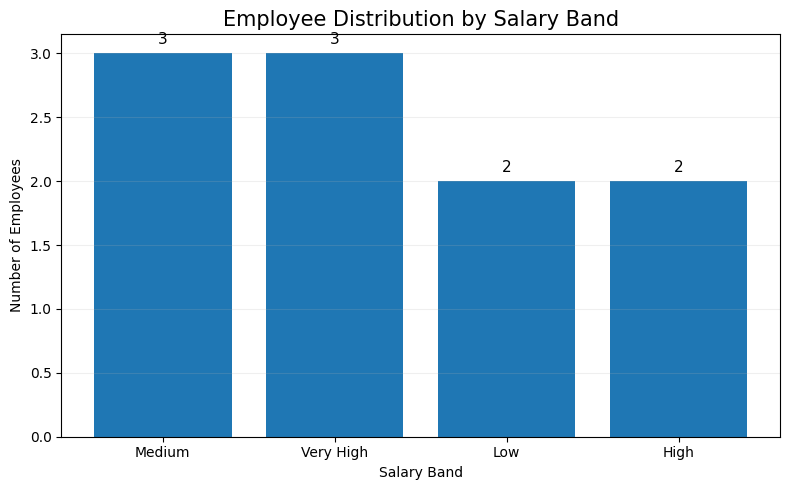

In [ ]:
# VISUALIZATION 1: Salary Band Distribution

band_counts = final_df["salary_band"].value_counts()

plt.figure(figsize=(8, 5))

bars = plt.bar(
    band_counts.index,
    band_counts.values
)

plt.title("Employee Distribution by Salary Band", fontsize=15)
plt.xlabel("Salary Band")
plt.ylabel("Number of Employees")

plt.grid(axis="y", alpha=0.2)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.05,
        str(int(height)),
        ha="center",
        va="bottom",
        fontsize=11
    )

plt.tight_layout()
plt.show()

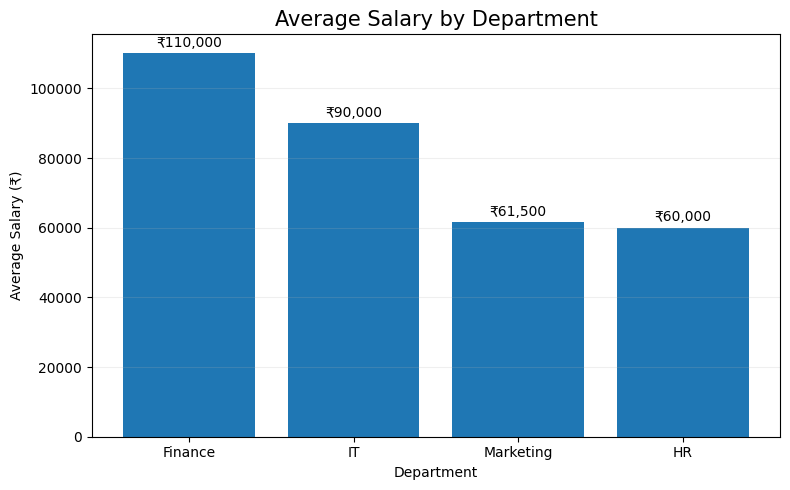

In [ ]:
# VISUALIZATION 2: Average Salary by Department

department_salary = (
    final_df
    .groupby("department")["salary"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))

bars = plt.bar(
    department_salary.index,
    department_salary.values
)

plt.title("Average Salary by Department", fontsize=15)
plt.xlabel("Department")
plt.ylabel("Average Salary (₹)")

plt.grid(axis="y", alpha=0.2)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 1000,
        f"₹{height:,.0f}",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.tight_layout()
plt.show()

In [ ]:
# FINAL ETL SUMMARY

print("╔══════════════════════════════════════════╗")
print("║        ETL PIPELINE COMPLETED           ║")
print("╚══════════════════════════════════════════╝")

print("\n🔵 EXTRACT")
print(f"   Records extracted : {source_count}")

print("\n🟠 TRANSFORM")
print("   Feature created   : salary_band")
print(f"   Average salary    : ₹{final_df['salary'].mean():,.2f}")

print("\n🟢 LOAD")
print(f"   Records loaded    : {target_count}")
print("   Target table      : employee_salary_bands")

print("\n🔍 VALIDATION")
print("   Status             : PASSED")

print("\n📊 VISUALIZATION")
print("   • Salary band distribution")
print("   • Department-wise average salary")

print("\n🎉 ETL PIPELINE SUCCESSFULLY COMPLETED!")

╔══════════════════════════════════════════╗
║        ETL PIPELINE COMPLETED           ║
╚══════════════════════════════════════════╝

🔵 EXTRACT
   Records extracted : 10

🟠 TRANSFORM
   Feature created   : salary_band
   Average salary    : ₹82,300.00

🟢 LOAD
   Records loaded    : 10
   Target table      : employee_salary_bands

🔍 VALIDATION
   Status             : PASSED

📊 VISUALIZATION
   • Salary band distribution
   • Department-wise average salary

🎉 ETL PIPELINE SUCCESSFULLY COMPLETED!


# Result

The PostgreSQL ETL pipeline was successfully implemented using Google Colab and Python.

The pipeline extracted employee salary data from the PostgreSQL `employee_source` table, performed data quality checks, transformed the data by creating the `salary_band` feature, and loaded the transformed records into the `employee_salary_bands` target table.

The ETL process was validated by comparing the source and target record counts, and the results were successfully visualized using salary-band distribution and department-wise average salary charts.

### Conclusion

The experiment demonstrates the complete Extract, Transform, and Load (ETL) process using PostgreSQL and Python/Pandas, along with data validation and visualization.